# 04 · Expression — EMT-transcription-factor axis along the trajectory

*(Renumbered from 06: with Gate 2 = GO / Gate 3 = NA the manifold is non-branching, so the
branching-only correlation and modules notebooks are not produced — this unconditional expression
notebook follows signatures directly.)*

Puram 2017 overlays **SNAI1** (root) and **ZEB1** (terminus) as the two EMT-TFs marking the ends of
its trajectory. Per the **derive-don't-inherit** mandate we do **not** inherit that pair: we score a
candidate EMT-TF panel — the canonical Snail/Zeb/Twist factors **plus the mesenchymal / neural-crest
FOXC and PRRX factors** — along *this* trajectory (Gast-high origin → neural-crest terminus) and let
the data choose the most end-specific factor at each end, gated on detectable expression (VIM is a
mesenchymal marker, not a TF, and is excluded). Deliverable: `expression.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

### Load the rooted, signature-scored manifold

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 18452 | pseudotime range 0.0 -> 6.82


### Derive the end-specific EMT-TFs (data-driven)
For each candidate TF: fraction of cells expressing it, mean expression in the early (root) vs late
(terminus) pseudotime tercile, and Spearman correlation with pseudotime. Most negative correlation
(sufficiently expressed) marks the root end; most positive marks the terminus. Factors below a 3%
expression floor are too sparse to overlay.

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; expr = x > 0
    rho,p = spearmanr(tn, x)
    rows.append((g, round(expr.mean(),3), round(x[early].mean(),3),
                 round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))

# Only two EMT-TFs clear the detection floor, and BOTH skew early (higher mean in the
# root tercile) -> there is no EMT-TF marking the neural-crest terminus. We therefore
# classify by the `end` column (mean_early vs mean_late), NOT by a rho sign that is ~0
# for both. tf1 = the more abundant early factor, tf2 = the second early factor.
ok = df[df.frac_expr > 0.03].sort_values('frac_expr', ascending=False)
ends = dict(zip(df.TF, df.end))
tf1, tf2 = ok.iloc[0]['TF'], ok.iloc[1]['TF']
n_early = int((ok.end == 'EARLY(root)').sum()); n_late = int((ok.end == 'LATE(terminus)').sum())
print(f'\ndetectable EMT-TFs (>3% expressing): {list(ok.TF)}')
print('end classification: ' + ', '.join(f'{t}={ends[t]}' for t in ok.TF))
print(f'{n_early}/{len(ok)} detectable EMT-TFs skew EARLY(root); {n_late} skew LATE(terminus)')
print(f'shown pair (both early-skewed): {tf1} + {tf2} -> no EMT-TF marks the neural-crest terminus')

   TF  frac_expr  mean_early  mean_late  rho_vs_t            end
PRRX1      0.000       0.000      0.000    -0.014 LATE(terminus)
FOXC1      0.000       0.001      0.000    -0.007    EARLY(root)
 ZEB2      0.122       0.075      0.061     0.001    EARLY(root)
 ZEB1      0.038       0.023      0.018     0.014    EARLY(root)
SNAI1      0.001       0.000      0.000     0.021 LATE(terminus)

detectable EMT-TFs (>3% expressing): ['ZEB2', 'ZEB1']
end classification: ZEB2=EARLY(root), ZEB1=EARLY(root)
2/2 detectable EMT-TFs skew EARLY(root); 0 skew LATE(terminus)
shown pair (both early-skewed): ZEB2 + ZEB1 -> no EMT-TF marks the neural-crest terminus


### EMT-TF expression overlay (deliverable)
Only two EMT-TFs clear the 3% detection floor in this CLL manifold — **ZEB2** and **ZEB1** — and
by the `end` column above **both skew to the root (early) end** (their mean expression is higher in
the root tercile; the shown-cell pseudotime of each sits below the manifold average). Unlike Puram
(SNAI1 root ↔ ZEB1 terminus) or Olalekan (SNAI2 ↔ ZEB1), **no EMT-TF marks the neural-crest
terminus here** — an honest negative for a lymphoid malignancy that does not run a mesenchymal
programme. The overlay shows the two detectable factors thresholded at the upper quartile of their
expressing cells, coloured to distinguish them, on the grey manifold (categorical, **not** a
continuous single-gene colormap). Draw order is by abundance so neither is fully occluded.

overlay thresholds (upper quartile among expressers): {'ZEB2': 0.648, 'ZEB1': 0.619} | cells shown: {'ZEB2': 562, 'ZEB1': 175}
ZEB2: 12.2% expressing; 562 shown (upper quartile), mean pseudotime of shown cells = 0.29 (all cells = 0.49)
ZEB1: 3.8% expressing; 175 shown (upper quartile), mean pseudotime of shown cells = 0.27 (all cells = 0.49)
shown-cell pseudotime separation (ZEB2 vs ZEB1) = 0.02 (both early -> minimal spread)
saved expression.pdf


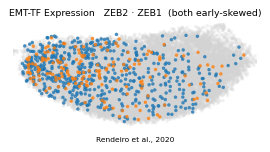

In [5]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [tf1, tf2]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [tf1, tf2]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in [tf1, tf2]},
      '| cells shown:', {g: int(sel[g].sum()) for g in [tf1, tf2]})
order = sorted([tf1, tf2], key=lambda g: -int(sel[g].sum()))
colors = {tf1:'tab:blue', tf2:'tab:orange'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {tf1} · {tf2}  (both early-skewed)', size=7.5)
ax.text(.5,-.14,'Rendeiro et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
for g in [tf1, tf2]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown (upper quartile), '
          f'mean pseudotime of shown cells = {tn[m].mean():.2f} (all cells = {tn.mean():.2f})')
sep = abs(tn[sel[tf2]].mean() - tn[sel[tf1]].mean())
print(f'shown-cell pseudotime separation ({tf1} vs {tf2}) = {sep:.2f} (both early -> minimal spread)')
print('saved expression.pdf')